# 11 — MLP on the hand-crafted features

The same 48 features as the LDA (MAV / RMS / WL x 16 channels), into two hidden layers of 128 ReLU units
(`src/nn.py`, `MLP`). Trained with torch (AdamW, class-balanced cross-entropy, early stopping on held-out 2 s blocks of
each class); inference is numpy from the exported weights, so a profile needs no torch.

Calibration (`loso`): fine-tunes only the output layer on the new subject's first *n* seconds per class.

Same protocol as `10`: DB5 exercise 1, train on repetitions 1–4, test on 5–6, every regime. Writes `runs/notebooks/mlp.json` for `15`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src import report

if Path.cwd().name == "notebooks":
    os.chdir("..")

In [2]:
FEATURES = {}
DECODER = {"decoder": {"name": "mlp", "params": {}}}
cfg, *data = report.features(FEATURES)
X, y, columns, info = data
print(f"{len(y)} windows x {X.shape[1]} features")

140145 windows x 48 features


## Every regime

In [3]:
summary = report.run_regimes({**FEATURES, **DECODER}, data)
latency = report.latency_us({**FEATURES, **DECODER}, data)
report.save(DECODER["decoder"]["name"], summary, latency)
print(f"decoder latency: {latency:.0f} µs per window")

per_user balanced 0.722 | macro-F1 0.674 | 43 s


pooled   balanced 0.653 | macro-F1 0.606 | 20 s


loso     balanced 0.357 | macro-F1 0.334 | 314 s


decoder latency: 15 µs per window


Against the LDA baseline (from `10`):

In [4]:
summaries = report.load_all()
names = [n for n in ("lda", DECODER["decoder"]["name"]) if n in summaries]
report.table({n: summaries[n] for n in names}).round(3)

accuracy  balanced_accuracy  macro_f1  worst_user_balanced  \
decoder regime                                                                 
lda     per_user     0.810              0.643     0.653                0.566   
        pooled       0.730              0.461     0.467                0.291   
        loso         0.701              0.389     0.393                0.234   
mlp     per_user     0.802              0.722     0.674                0.604   
        pooled       0.770              0.653     0.606                0.532   
        loso         0.616              0.357     0.334                0.241   

                  switches_per_s  latency_us  evaluation_s  
decoder regime                                              
lda     per_user           2.468       7.375         0.940  
        pooled             3.519       7.375         0.156  
        loso               3.690       7.375         1.876  
mlp     per_user           2.554      14.791        42.887  
        pooled             3.923      14.791        20.397  
        loso               5.448      14.791       313.755

## Calibration effort

Dashed: a new decoder per subject from *n* seconds per class. Solid: the decoder of the other nine subjects, adapted with them.

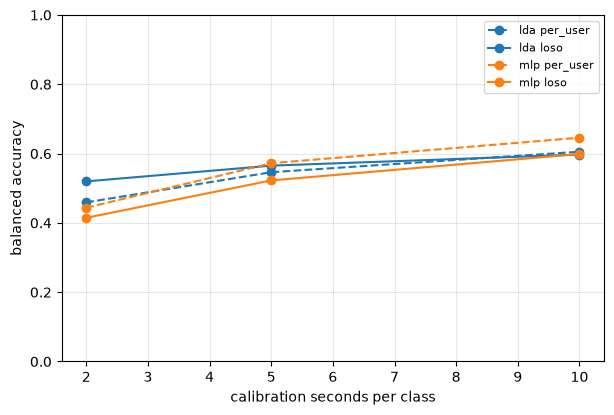

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
report.plot_calibration(ax, {n: summaries[n] for n in names})

## Confusions (per_user)

per_user    0.861
pooled      0.855
loso        0.796
Name: rest recall, dtype: float64

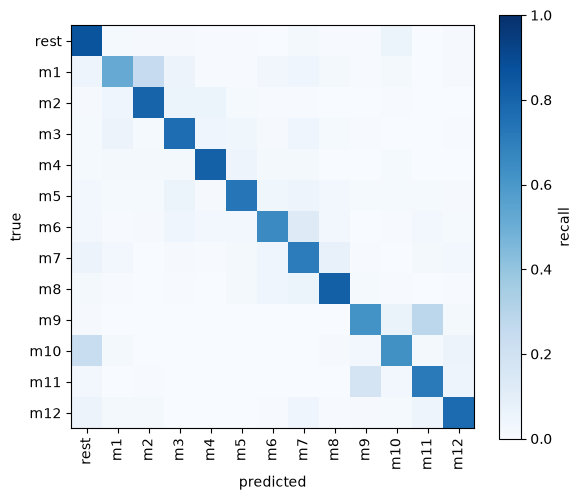

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = report.plot_confusion(ax, summary["per_user"]["y_true"], summary["per_user"]["y_pred"], info["label_names"])
fig.colorbar(im, label="recall")
pd.Series({regime: s["recall"]["rest"] for regime, s in summary.items()}, name="rest recall").round(3)